<a href="https://colab.research.google.com/github/NinhHTK/Documents/blob/main/SE196288_Lab3%264.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

---
```
Course: DSR301m
Lab: 03 & 04
Name: Hà Thúc Khương Ninh
ID: SE196288
Class: AI2007
```
---
**Submission File**:
* Use **your StudentID** as file name (e.g., SE123456.ipynb)

* Only submit notebook file (.ipynb)

* Submit only once; if multiple submissions are made, the last file will be used, and points will be deducted.

**Deadline for submission: 22:00:00 PM on 27/10/2026**

**Late submission**: $-30\%$

**Link for submission**: https://forms.gle/oS2EVgoLjUnmAJbG7


1. Install and load the `penguins` dataset from the `palmerpenguins` package.


In [1]:
# Kiểm tra và cài đặt thư viện 'palmerpenguins' nếu chưa có
if (!requireNamespace("palmerpenguins", quietly = TRUE)) {
  install.packages("palmerpenguins", repos = "http://cran.us.r-project.org")
}
# Load thư viện palmerpenguins
library(palmerpenguins)

# Tải tập dữ liệu penguins
data(penguins)

# Loại bỏ các dòng có chứa giá trị khuyết thiếu (NA)
penguins_clean <- na.omit(penguins)

# In ra kích thước của tập dữ liệu sau khi làm sạch (Số dòng, Số cột)
print(dim(penguins_clean))

# Hiển thị 6 dòng đầu tiên của tập dữ liệu
head(penguins_clean)


Attaching package: ‘palmerpenguins’


The following objects are masked from ‘package:datasets’:

    penguins, penguins_raw




[1] 333   8


species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
<fct>,<fct>,<dbl>,<dbl>,<int>,<int>,<fct>,<int>
Adelie,Torgersen,39.1,18.7,181,3750,male,2007
Adelie,Torgersen,39.5,17.4,186,3800,female,2007
Adelie,Torgersen,40.3,18.0,195,3250,female,2007
Adelie,Torgersen,36.7,19.3,193,3450,female,2007
Adelie,Torgersen,39.3,20.6,190,3650,male,2007
Adelie,Torgersen,38.9,17.8,181,3625,female,2007


2. Visualize the dataset using PCA and discuss the results.


=== PCA SUMMARY ===
Importance of components:
                          PC1    PC2     PC3     PC4
Standard deviation     1.6569 0.8821 0.60716 0.32846
Proportion of Variance 0.6863 0.1945 0.09216 0.02697
Cumulative Proportion  0.6863 0.8809 0.97303 1.00000

=== PCA ROTATION (LOADINGS) ===
                     PC1    PC2    PC3    PC4
bill_length_mm     0.454 -0.600 -0.642  0.145
bill_depth_mm     -0.399 -0.796  0.426 -0.160
flipper_length_mm  0.577 -0.006  0.236 -0.782
body_mass_g        0.550 -0.076  0.592  0.585


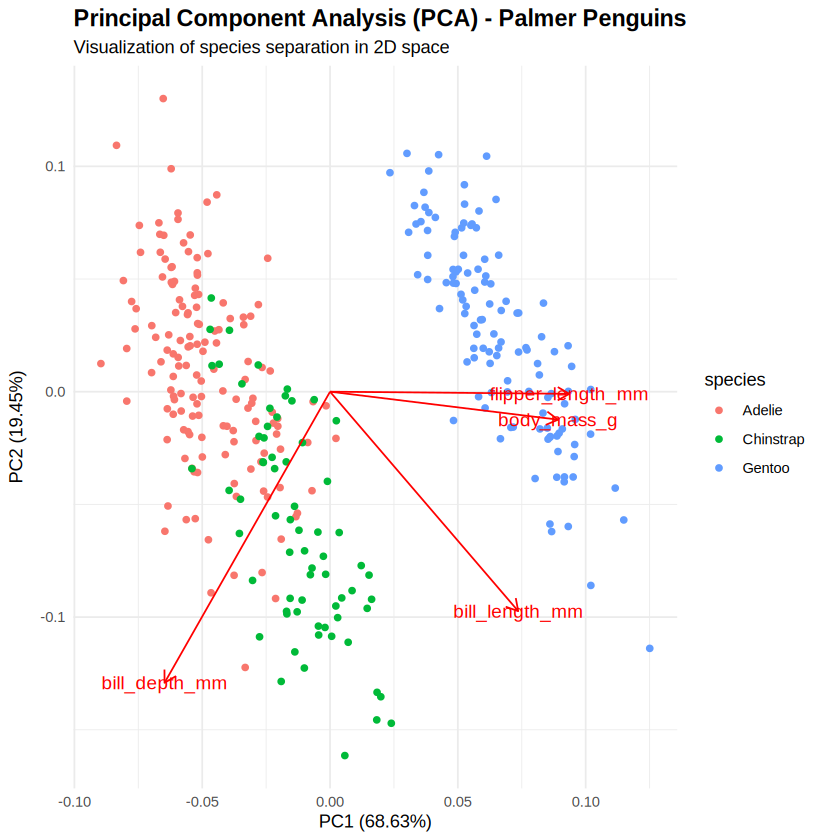

In [2]:
# Kiểm tra và cài đặt thư viện 'ggfortify' để hỗ trợ vẽ đồ thị PCA
if (!requireNamespace("ggfortify", quietly = TRUE)) {
  install.packages("ggfortify", repos = "http://cran.us.r-project.org")
}
# Load các thư viện cần thiết cho việc trực quan hóa
library(ggplot2)
library(ggfortify)

# Lọc ra các biến số liên tục để thực hiện phân tích PCA
num_vars <- penguins_clean[, c("bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g")]

# Thực hiện phân tích thành phần chính (PCA) có chuẩn hóa dữ liệu (scale. = TRUE)
pca_res <- prcomp(num_vars, scale. = TRUE)

# In kết quả tóm tắt của PCA (Tỷ lệ phương sai giải thích)
cat("=== PCA SUMMARY ===\n")
print(summary(pca_res))

# In ma trận xoay (Loadings) để xem đóng góp của các biến vào từng PC
cat("\n=== PCA ROTATION (LOADINGS) ===\n")
print(round(pca_res$rotation, 3))

# Vẽ biểu đồ thực thể PCA (Biplot) phân nhóm theo loài chim cánh cụt
pca_plot <- autoplot(pca_res, data = penguins_clean, colour = 'species', loadings = TRUE,
                     loadings.label = TRUE, loadings.label.size = 4, loadings.colour = 'red',
                     loadings.label.colour = 'red') +
  theme_minimal() +
  labs(title = "Principal Component Analysis (PCA) - Palmer Penguins",
       subtitle = "Visualization of species separation in 2D space") +
  theme(plot.title = element_text(face = "bold", size = 14),
        legend.position = "right")

# Hiển thị đồ thị PCA
print(pca_plot)

### PCA Results
- PC1 explains 68.63% of the variance and reflects overall body size (flipper_length_mm: 0.577, body_mass_g: 0.550); bill_depth_mm loads negatively (-0.399).
- PC2 explains 19.45% of the variance and reflects overall bill size (bill_length_mm: -0.600, bill_depth_mm: -0.796). PC1 and PC2 together explain 88.09%.
- Gentoo forms a distinct cluster on the positive PC1 side. Adelie and Chinstrap are separated mainly along PC2, with some overlap.

3. Split the data into training and test sets with an 80:20 ratio.


In [3]:
# Thiết lập seed để đảm bảo kết quả phân chia dữ liệu có thể tái lập
set.seed(42)

# Lấy tổng số dòng của dữ liệu penguins đã làm sạch
n <- nrow(penguins_clean)

# Lấy ngẫu nhiên chỉ số dòng cho tập Train (80% dữ liệu)
train_idx <- sample(1:n, size = round(0.8 * n))

# Tạo tập huấn luyện (Train) và tập kiểm thử (Test)
train_set <- penguins_clean[train_idx, ]
test_set <- penguins_clean[-train_idx, ]

# In ra kích thước của hai tập dữ liệu
cat("Training set size:", nrow(train_set), "\n")
cat("Testing set size:", nrow(test_set), "\n")

Training set size: 266 
Testing set size: 67 


4. Choose 2 machine learning models, then train and test it.


In [4]:
# Kiểm tra và cài đặt thư viện 'randomForest' để xây dựng mô hình
if (!requireNamespace("randomForest", quietly = TRUE)) {
  install.packages("randomForest", repos = "http://cran.us.r-project.org")
}
# Load thư viện Random Forest
library(randomForest)

# Thiết lập seed trước khi chạy Random Forest để đảm bảo tính ổn định
set.seed(42)

# Huấn luyện mô hình Random Forest phân loại loài dựa trên 4 đặc trưng sinh học
rf_model <- randomForest(species ~ bill_length_mm + bill_depth_mm + flipper_length_mm + body_mass_g,
                         data = train_set, importance = TRUE)

# In thông tin tóm tắt của mô hình Random Forest (Sai số OOB, Confusion Matrix trên tập Train)
print(rf_model)

randomForest 4.7-1.2

Type rfNews() to see new features/changes/bug fixes.


Attaching package: ‘randomForest’


The following object is masked from ‘package:ggplot2’:

    margin





Call:
 randomForest(formula = species ~ bill_length_mm + bill_depth_mm +      flipper_length_mm + body_mass_g, data = train_set, importance = TRUE) 
               Type of random forest: classification
                     Number of trees: 500
No. of variables tried at each split: 2

        OOB estimate of  error rate: 2.26%
Confusion matrix:
          Adelie Chinstrap Gentoo class.error
Adelie       110         3      0  0.02654867
Chinstrap      3        51      0  0.05555556
Gentoo         0         0     99  0.00000000


In [5]:
# Dự đoán nhãn loài chim cánh cụt trên tập huấn luyện (Train set)
pred_rf_train <- predict(rf_model, train_set)

# Dự đoán nhãn loài chim cánh cụt trên tập kiểm thử (Test set)
pred_rf_test <- predict(rf_model, test_set)

In [6]:
# Kiểm tra và cài đặt thư viện 'rpart' để xây dựng cây quyết định
if (!requireNamespace("rpart", quietly = TRUE)) {
  install.packages("rpart", repos = "http://cran.us.r-project.org")
}
# Load thư viện rpart
library(rpart)

# Huấn luyện mô hình Cây quyết định (Decision Tree) với phương pháp phân loại (class)
dt_model <- rpart(species ~ bill_length_mm + bill_depth_mm + flipper_length_mm + body_mass_g, data = train_set, method = "class")

# In ra các quy tắc phân nhánh của Cây quyết định
print(dt_model)

n= 266 

node), split, n, loss, yval, (yprob)
      * denotes terminal node

1) root 266 153 Adelie (0.42481203 0.20300752 0.37218045)  
  2) flipper_length_mm< 206.5 161  50 Adelie (0.68944099 0.30434783 0.00621118)  
    4) bill_length_mm< 43.35 112   3 Adelie (0.97321429 0.02678571 0.00000000) *
    5) bill_length_mm>=43.35 49   3 Chinstrap (0.04081633 0.93877551 0.02040816) *
  3) flipper_length_mm>=206.5 105   7 Gentoo (0.01904762 0.04761905 0.93333333)  
    6) bill_depth_mm>=17.65 7   2 Chinstrap (0.28571429 0.71428571 0.00000000) *
    7) bill_depth_mm< 17.65 98   0 Gentoo (0.00000000 0.00000000 1.00000000) *


In [7]:
# Dự đoán nhãn loài bằng Cây quyết định trên tập huấn luyện (Train set)
pred_dt_train <- predict(dt_model, train_set, type = "class")

# Dự đoán nhãn loài bằng Cây quyết định trên tập kiểm thử (Test set)
pred_dt_test <- predict(dt_model, test_set, type = "class")

5. Show the confusion matrices for two methods on the training and test sets, and discuss the results.


In [8]:
# Tính toán độ chính xác (Accuracy) trên tập huấn luyện cho cả 2 mô hình
acc_rf_train <- mean(pred_rf_train == train_set$species) * 100
acc_dt_train <- mean(pred_dt_train == train_set$species) * 100

cat("========================================================\n")
cat("        TRAINING SET EVALUATION (N = 266)\n")
cat("========================================================\n\n")

# Hiển thị kết quả đánh giá mô hình Random Forest trên tập Train
cat("1. Random Forest Classifier (Training Partition)\n")
cat("Training Accuracy:", round(acc_rf_train, 2), "%\n")
cat("--------------------------------------------------------\n")
rf_train_table <- table(Predicted = pred_rf_train, Actual = train_set$species)
print(rf_train_table)
cat("\n")

# Hiển thị kết quả đánh giá mô hình Decision Tree trên tập Train
cat("2. Decision Tree Classifier (Training Partition)\n")
cat("Training Accuracy:", round(acc_dt_train, 2), "%\n")
cat("--------------------------------------------------------\n")
dt_train_table <- table(Predicted = pred_dt_train, Actual = train_set$species)
print(dt_train_table)

        TRAINING SET EVALUATION (N = 266)

1. Random Forest Classifier (Training Partition)
Training Accuracy: 100 %
--------------------------------------------------------
           Actual
Predicted   Adelie Chinstrap Gentoo
  Adelie       113         0      0
  Chinstrap      0        54      0
  Gentoo         0         0     99

2. Decision Tree Classifier (Training Partition)
Training Accuracy: 96.99 %
--------------------------------------------------------
           Actual
Predicted   Adelie Chinstrap Gentoo
  Adelie       109         3      0
  Chinstrap      4        51      1
  Gentoo         0         0     98


### Training Set Results
- **Random Forest:** 100% training accuracy. This is optimistic because the model is evaluated on its own training data, so the OOB error (2.26%) and test accuracy (98.51%) are more realistic.
- **Decision Tree:** 96.99% training accuracy. The first split on flipper length mostly isolates Gentoo; later splits separate Adelie and Chinstrap.

In [9]:
# Tính toán độ chính xác (Accuracy) trên tập kiểm thử (Test set)
acc_rf_test <- mean(pred_rf_test == test_set$species) * 100
acc_dt_test <- mean(pred_dt_test == test_set$species) * 100

cat("========================================================\n")
cat("          TEST SET EVALUATION (N = 67)\n")
cat("========================================================\n\n")

# Hiển thị kết quả đánh giá mô hình Random Forest trên tập Test
cat("1. Random Forest Classifier (Test Partition)\n")
cat("Test Accuracy:", round(acc_rf_test, 2), "%\n")
cat("--------------------------------------------------------\n")
rf_test_table <- table(Predicted = pred_rf_test, Actual = test_set$species)
print(rf_test_table)
cat("\n")

# Hiển thị kết quả đánh giá mô hình Decision Tree trên tập Test
cat("2. Decision Tree Classifier (Test Partition)\n")
cat("Test Accuracy:", round(acc_dt_test, 2), "%\n")
cat("--------------------------------------------------------\n")
dt_test_table <- table(Predicted = pred_dt_test, Actual = test_set$species)
print(dt_test_table)

          TEST SET EVALUATION (N = 67)

1. Random Forest Classifier (Test Partition)
Test Accuracy: 98.51 %
--------------------------------------------------------
           Actual
Predicted   Adelie Chinstrap Gentoo
  Adelie        32         0      0
  Chinstrap      1        14      0
  Gentoo         0         0     20

2. Decision Tree Classifier (Test Partition)
Test Accuracy: 94.03 %
--------------------------------------------------------
           Actual
Predicted   Adelie Chinstrap Gentoo
  Adelie        31         2      0
  Chinstrap      2        12      0
  Gentoo         0         0     20


### Test Set Results
| Metric | Random Forest | Decision Tree |
| :--- | :---: | :---: |
| Test accuracy | 98.51% | 94.03% |
| Misclassifications | 1 / 67 | 4 / 67 |

- Gentoo is never misclassified, matching its separation on the PCA plot. All errors are Adelie ↔ Chinstrap.
- With only 67 test samples, the 1 vs 4 error difference is not statistically conclusive.

 6. Do the results stay good when you use fewer features? Try it and discuss.

In [10]:
library(randomForest)

# Định nghĩa các tập hợp con đặc trưng (Subset Features) khác nhau để thử nghiệm
feature_sets <- list(
  All_4 = c("bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"),
  BillLen_Flipper = c("bill_length_mm", "flipper_length_mm"),
  BillLen_BillDepth = c("bill_length_mm", "bill_depth_mm"),
  Flipper_BodyMass = c("flipper_length_mm", "body_mass_g")
)

# Khởi tạo danh sách lưu giá trị trung bình và độ lệch chuẩn của độ chính xác
results_mean <- list()
results_sd <- list()

# Thực hiện lặp qua từng bộ đặc trưng
for (name in names(feature_sets)) {
  acc_runs <- c()
  # Thực hiện lặp 20 lần với các seed khác nhau để giảm thiểu biến động ngẫu nhiên
  for (seed in 1:20) {
    set.seed(seed)
    n_exp <- nrow(penguins_clean)
    # Chia tập dữ liệu 80:20 ngẫu nhiên theo seed hiện tại
    train_idx_exp <- sample(1:n_exp, size = round(0.8 * n_exp))
    train_exp <- penguins_clean[train_idx_exp, ]
    test_exp <- penguins_clean[-train_idx_exp, ]

    # Tạo công thức mô hình tương ứng với bộ đặc trưng hiện tại
    formula_exp <- as.formula(paste("species ~", paste(feature_sets[[name]], collapse = " + ")))
    # Huấn luyện mô hình Random Forest
    rf_exp <- randomForest(formula_exp, data = train_exp)
    # Dự đoán trên tập kiểm thử
    pred_exp <- predict(rf_exp, test_exp)
    # Lưu độ chính xác của lượt chạy này
    acc_runs <- c(acc_runs, mean(pred_exp == test_exp$species) * 100)
  }
  # Lưu giá trị trung bình (Mean) và độ lệch chuẩn (SD) sau 20 lượt chạy
  results_mean[[name]] <- mean(acc_runs)
  results_sd[[name]] <- sd(acc_runs)
}

# In kết quả thực nghiệm ra màn hình
cat("========================================================\n")
cat("      SUBSET EXPERIMENT EVALUATION (20 RANDOM SEEDS)   \n")
cat("========================================================\n\n")
for (name in names(feature_sets)) {
  cat(sprintf("%-18s: Mean Accuracy = %6.2f%% | SD = %5.2f%%\n",
              name, results_mean[[name]], results_sd[[name]]))
}

      SUBSET EXPERIMENT EVALUATION (20 RANDOM SEEDS)   

All_4             : Mean Accuracy =  97.54% | SD =  2.34%
BillLen_Flipper   : Mean Accuracy =  96.19% | SD =  2.30%
BillLen_BillDepth : Mean Accuracy =  96.42% | SD =  2.02%
Flipper_BodyMass  : Mean Accuracy =  77.91% | SD =  3.77%


### Fewer Features

Yes, if the features are chosen wisely. Bill Length + Bill Depth (96.42%) and Bill Length + Flipper (96.19%) are close to all 4 features (97.54%), and the drop is smaller than the SD (~2.3%). Using only Flipper + Body Mass drops accuracy to 77.91%, because size alone cannot separate Adelie from Chinstrap.

7. Show the importance of each feature and discuss which ones matter most.


Attaching package: ‘gridExtra’


The following object is masked from ‘package:randomForest’:

    combine




=== EXACT RANDOM FOREST IMPORTANCE METRICS ===
                  Adelie Chinstrap Gentoo MeanDecreaseAccuracy MeanDecreaseGini
bill_length_mm    130.97     63.93  15.31               102.99            67.26
bill_depth_mm      19.12     23.68  44.04                47.02            35.49
flipper_length_mm  20.10     22.75  26.71                32.00            51.62
body_mass_g         7.25     21.70  16.63                23.39            15.05



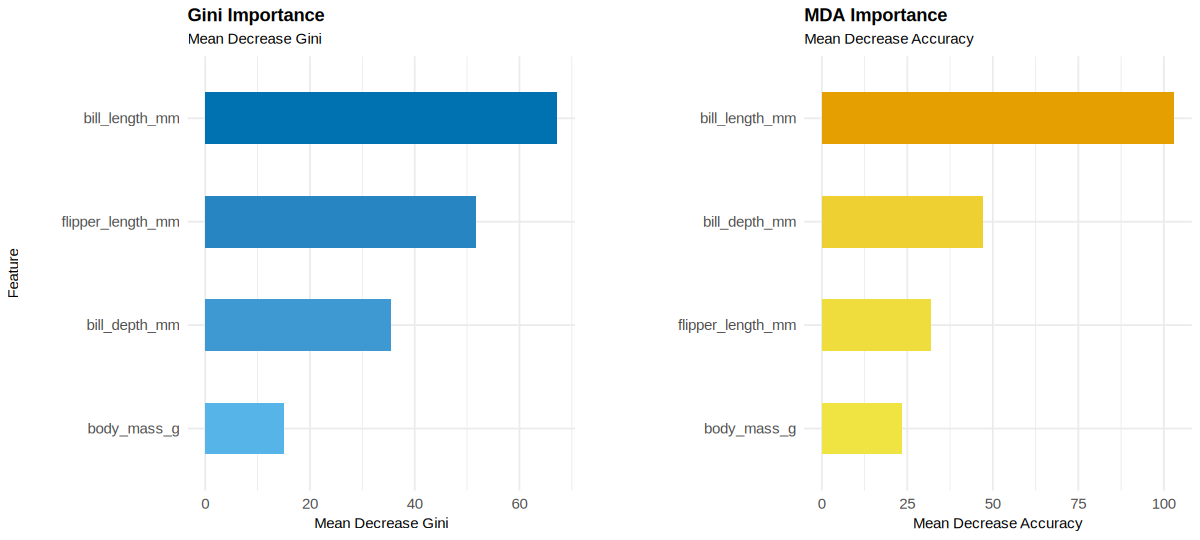

In [11]:
# Kiểm tra và cài đặt thư viện 'gridExtra' để hiển thị biểu đồ song song
if (!requireNamespace("gridExtra", quietly = TRUE)) {
  install.packages("gridExtra", repos = "http://cran.us.r-project.org")
}
library(gridExtra)
library(ggplot2)
library(randomForest)

# Trích xuất bảng đo lường mức độ quan trọng từ mô hình Random Forest
imp_matrix <- importance(rf_model)
cat("=== EXACT RANDOM FOREST IMPORTANCE METRICS ===\n")
print(round(imp_matrix, 2))
cat("\n")

# Chuyển đổi ma trận tầm quan trọng thành DataFrame
imp_df <- data.frame(
  Feature = rownames(imp_matrix),
  MeanDecreaseAccuracy = imp_matrix[, "MeanDecreaseAccuracy"],
  MeanDecreaseGini = imp_matrix[, "MeanDecreaseGini"]
)

# Biểu đồ Gini với căn chỉnh lề tối ưu hơn (sử dụng ggplot2::margin để tránh xung đột)
plot_gini <- ggplot(imp_df, aes(x = reorder(Feature, MeanDecreaseGini), y = MeanDecreaseGini, fill = MeanDecreaseGini)) +
  geom_bar(stat = "identity", width = 0.5) +
  coord_flip() +
  scale_fill_gradient(low = "#56B4E9", high = "#0072B2") +
  theme_minimal() +
  labs(title = "Gini Importance",
       subtitle = "Mean Decrease Gini",
       x = "Feature",
       y = "Mean Decrease Gini") +
  theme(plot.title = element_text(face = "bold", size = 11),
        plot.subtitle = element_text(size = 9),
        axis.title = element_text(size = 9),
        axis.text = element_text(size = 9),
        legend.position = "none",
        plot.margin = ggplot2::margin(5, 15, 5, 5))

# Biểu đồ MDA với căn chỉnh lề tối ưu hơn (sử dụng ggplot2::margin để tránh xung đột)
plot_mda <- ggplot(imp_df, aes(x = reorder(Feature, MeanDecreaseAccuracy), y = MeanDecreaseAccuracy, fill = MeanDecreaseAccuracy)) +
  geom_bar(stat = "identity", width = 0.5) +
  coord_flip() +
  scale_fill_gradient(low = "#F0E442", high = "#E69F00") +
  theme_minimal() +
  labs(title = "MDA Importance",
       subtitle = "Mean Decrease Accuracy",
       x = "",
       y = "Mean Decrease Accuracy") +
  theme(plot.title = element_text(face = "bold", size = 11),
        plot.subtitle = element_text(size = 9),
        axis.title = element_text(size = 9),
        axis.text = element_text(size = 9),
        legend.position = "none",
        plot.margin = ggplot2::margin(5, 5, 5, 15))

# Thiết lập kích thước đầu ra hiển thị rộng ngang
options(repr.plot.width = 10, repr.plot.height = 4.5)

# Sắp xếp và hiển thị song song hai biểu đồ
grid.arrange(plot_gini, plot_mda, ncol = 2)

### Feature Importance

By MDA the ranking is bill_length (102.99) > bill_depth (47.02) > flipper (32.00) > body_mass (23.39); by Gini, flipper (51.62) ranks above bill_depth (35.49). The two measures disagree on 2nd place, since Gini favors correlated size variables (flipper, body mass). They agree that bill_length matters most and body_mass least.

**Conclusion**: bill length is the key feature. Keeping at least one bill variable is necessary, since removing both (Flipper + Body Mass) drops accuracy to 77.91%.